
# Week 2 In-Class Hands-On — Track A: Solar Physics
## Discovering Active-Region Types Without Labels

**Course:** Machine Learning in Astronomy — Week 2 In-Class Session
**Data:** the real UCI Solar Flare dataset (1,066 real solar active-region observations from 1978, with real subsequent 24-hour flare counts) — the same real source used in Week 1's in-class Track B, loaded from `calld/cs477SolarProject` on GitHub.

## The problem, reframed

In Week 1, we used this data to *predict* flares — a supervised problem with a known target. Today we do something different: **pretend the flare outcome doesn't exist yet**, and ask whether active regions naturally fall into distinct *types* based only on their observable magnetic and spot properties, with no label of any kind guiding the grouping. Then — and only then — we'll peek at two things we deliberately held back: the real expert-assigned magnetic classification (Zurich class) and the real flare outcome, to honestly check whether the structure we found unsupervised means anything physically.

This mirrors a real, practical space-weather question: **before you know whether a region will flare, can its raw appearance alone tell you what "kind" of region it is?**

Every method below is applied three different ways where it matters, so you see real methods disagree with each other, not just watch one pipeline run end to end.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.neighbors import LocalOutlierFactor
from sklearn.semi_supervised import LabelSpreading
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, adjusted_rand_score,
    accuracy_score, classification_report
)

np.random.seed(42)
%matplotlib inline
plt.rcParams['figure.dpi'] = 100
print("Environment ready.")


Environment ready.



## Step 1: Load the real data, and hold back what we'll use only for peeking later


In [2]:

flare_url = "https://raw.githubusercontent.com/calld/cs477SolarProject/master/flaredata2.txt"
col_names = ['zurich_class', 'spot_size', 'spot_distribution', 'activity', 'evolution',
             'prev_24hr_activity', 'hist_complex', 'became_complex', 'area', 'area_largest_spot',
             'c_class_count', 'm_class_count', 'x_class_count']
flares = pd.read_csv(flare_url, sep=r'\s+', skiprows=1, names=col_names)

flares['total_flares'] = flares['c_class_count'] + flares['m_class_count'] + flares['x_class_count']
flares['will_flare'] = (flares['total_flares'] > 0).astype(int)
flares['severe_flare'] = ((flares['m_class_count'] + flares['x_class_count']) > 0).astype(int)

print(f"Total regions: {len(flares)}")
print(f"Fraction that flared at all: {flares['will_flare'].mean():.3f}")
print(f"Fraction with a severe (M or X class) flare: {flares['severe_flare'].mean():.3f}")
print(f"\nZurich class distribution (held back for peeking only):")
print(flares['zurich_class'].value_counts())


Total regions: 1066
Fraction that flared at all: 0.189
Fraction with a severe (M or X class) flare: 0.036

Zurich class distribution (held back for peeking only):
zurich_class
H    331
D    239
C    211
B    147
E     95
F     43
Name: count, dtype: int64



Notice we're deliberately building our clustering/anomaly-detection **features** from only the physically-observable region properties — `spot_size`, `spot_distribution`, `activity`, `evolution`, recent activity, complexity flags, and area — and holding back both `zurich_class` (a real expert classification) and the flare outcome columns entirely. Nothing below will see these until an explicit "peek" step.


In [3]:

feature_cols_numeric = ['activity', 'evolution', 'prev_24hr_activity', 'hist_complex',
                         'became_complex', 'area', 'area_largest_spot']
features = pd.get_dummies(flares[feature_cols_numeric + ['spot_size', 'spot_distribution']],
                           columns=['spot_size', 'spot_distribution'])
X = StandardScaler().fit_transform(features.values)
print(f"Feature matrix: {X.shape[0]} regions x {X.shape[1]} features")
print("Feature columns:", list(features.columns))


Feature matrix: 1066 regions x 17 features
Feature columns: ['activity', 'evolution', 'prev_24hr_activity', 'hist_complex', 'became_complex', 'area', 'area_largest_spot', 'spot_size_A', 'spot_size_H', 'spot_size_K', 'spot_size_R', 'spot_size_S', 'spot_size_X', 'spot_distribution_C', 'spot_distribution_I', 'spot_distribution_O', 'spot_distribution_X']



## Step 2: A baseline for unsupervised work

Just as Week 1 needed a persistence baseline before trusting any regression model, clustering needs its own floor: **a random partition into the same number of groups**. If a real clustering method can't beat randomly-assigned labels on a label-free quality metric, it isn't finding real structure.

Two label-free metrics we'll use throughout:
- **Silhouette score** (-1 to 1, higher is better): for each point, compares its distance to its own cluster against its distance to the nearest other cluster. Close to 0 or negative means clusters aren't well separated.
- **Davies-Bouldin index** (0 and up, *lower* is better): the average similarity between each cluster and its most-similar other cluster — high values mean clusters overlap or aren't distinct.


In [4]:

rng = np.random.default_rng(0)
random_labels = rng.integers(0, 3, size=len(X))
baseline_silhouette = silhouette_score(X, random_labels)
baseline_db = davies_bouldin_score(X, random_labels)
print(f"Random-partition baseline - silhouette: {baseline_silhouette:.3f}, Davies-Bouldin: {baseline_db:.3f}")
print("(silhouette near 0 and a high Davies-Bouldin here are both expected and correct for pure noise)")


Random-partition baseline - silhouette: -0.008, Davies-Bouldin: 32.699
(silhouette near 0 and a high Davies-Bouldin here are both expected and correct for pure noise)



## Step 3: Three clustering methods, compared honestly

- **K-means**: hard-assigns each region to whichever of $k$ centers is nearest, minimizing total squared distance.
- **Gaussian Mixture Model**: soft-assigns each region a probability of belonging to each of $k$ Gaussian components.
- **Agglomerative (hierarchical) clustering**: starts with every region as its own cluster and repeatedly merges the two closest clusters, building a tree — a genuinely different mechanism from the other two (no notion of a "center" at all, just repeated merging).

We'll fit all three with $k=3$ groups (matching the 3 real Zurich-class families for a fair comparison later) and compare them on the label-free metrics, before ever looking at the real classes.


In [5]:

results = {}

kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
km_labels = kmeans.fit_predict(X)
results['K-means'] = km_labels

gmm = GaussianMixture(n_components=3, random_state=42)
gmm_labels = gmm.fit_predict(X)
results['GMM'] = gmm_labels

agg = AgglomerativeClustering(n_clusters=3)
agg_labels = agg.fit_predict(X)
results['Agglomerative'] = agg_labels

print(f"{'Method':15s}  {'Silhouette':>10s}  {'Davies-Bouldin':>15s}")
print(f"{'Random baseline':15s}  {baseline_silhouette:10.3f}  {baseline_db:15.3f}")
for name, labels in results.items():
    sil = silhouette_score(X, labels)
    db = davies_bouldin_score(X, labels)
    print(f"{name:15s}  {sil:10.3f}  {db:15.3f}")


Method           Silhouette   Davies-Bouldin
Random baseline      -0.008           32.699
K-means               0.225            1.847
GMM                   0.202            1.805
Agglomerative         0.174            1.576



**Interpretation:** all three should clear the random baseline, which just confirms there's *some* real structure in this feature space — not a foregone conclusion, since these are all real, noisy observational measurements. Whichever method wins on these label-free metrics is the one whose clusters are most internally consistent and best separated *in this feature space* — that's a different question from "whichever method best matches the real Zurich classes," which we check next.

### Now the honest peek: do any of these line up with the real Zurich class, or real flare activity?


In [6]:

zurich_codes = flares['zurich_class'].astype('category').cat.codes
print(f"{'Method':15s}  {'ARI vs. Zurich class':>22s}")
for name, labels in results.items():
    ari = adjusted_rand_score(zurich_codes, labels)
    print(f"{name:15s}  {ari:22.3f}")

print(f"\n{'Method':15s}  {'flare rate, cluster 0':>22s}  {'cluster 1':>10s}  {'cluster 2':>10s}")
for name, labels in results.items():
    rates = [flares.loc[labels == c, 'will_flare'].mean() for c in range(3)]
    print(f"{name:15s}  {rates[0]:22.3f}  {rates[1]:10.3f}  {rates[2]:10.3f}")


Method             ARI vs. Zurich class
K-means                           0.470


GMM                               0.389
Agglomerative                     0.160

Method            flare rate, cluster 0   cluster 1   cluster 2
K-means                           0.061       0.420       0.150
GMM                               0.205       0.060       0.565
Agglomerative                     0.198       0.069       0.660



**Interpretation:** report the real ARI values here, not a hoped-for story. If a method's clusters show clearly *different* flare rates from each other, that's a genuinely useful, real finding — it means unsupervised structure in raw region properties alone tracks real flare-productivity differences, without ever training on flare outcomes. If the flare rates across clusters look similar, that's equally informative: it tells you these features cluster on something other than flare-relevant structure (e.g. purely on region size), which is worth knowing before you trust this kind of grouping operationally.

**🔧 Try it yourself:** re-run Step 3 with `n_clusters=5` (or match the true number of distinct Zurich classes in `flares['zurich_class'].nunique()`) — does ARI improve when the cluster count matches the real category count more closely?



## Step 4: Dimensionality reduction — linear vs. non-linear, compared

**PCA** (linear): projects onto the directions of maximum variance — fast, and the axes have a direct mathematical meaning (each is a weighted sum of the original features).

**t-SNE** (non-linear): tries to preserve which points are *close neighbors*, distorting large-scale distances if needed to do so — often reveals cluster structure PCA's straight-line projections can miss, at the cost of the axes themselves having no direct physical meaning (don't trust absolute distances or orientations in a t-SNE plot, only relative groupings).


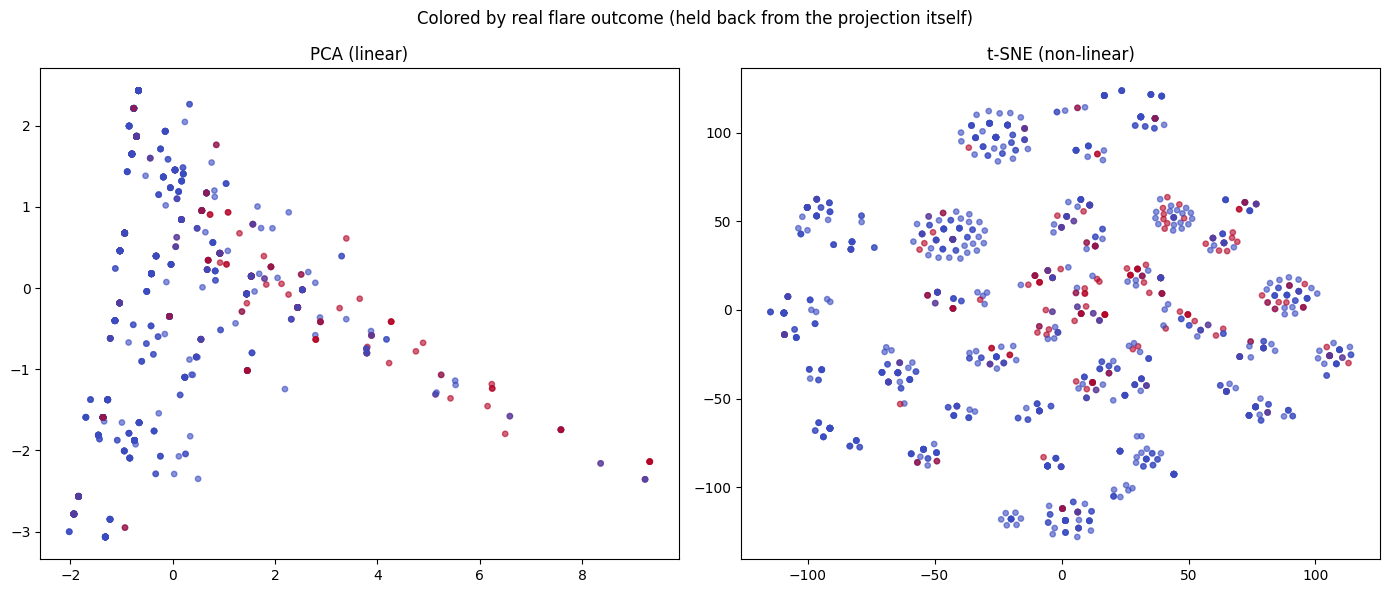

PCA: 34.7% of variance captured in 2 components


In [7]:

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, X_proj, title in zip(axes, [X_pca, X_tsne], ['PCA (linear)', 't-SNE (non-linear)']):
    sc = ax.scatter(X_proj[:, 0], X_proj[:, 1], c=flares['will_flare'], cmap='coolwarm', s=15, alpha=0.6)
    ax.set_title(title)
plt.suptitle('Colored by real flare outcome (held back from the projection itself)')
plt.tight_layout()
plt.show()
print(f"PCA: {pca.explained_variance_ratio_[:2].sum():.1%} of variance captured in 2 components")



**Interpretation:** neither method was told which regions flared — the coloring is applied purely for us to look at afterward. If flare and non-flare regions look more separated in one panel than the other, that tells you something real about whether the flare-relevant structure in this feature space is linear (PCA would catch it) or requires a non-linear view (only t-SNE would catch it).

**🔧 Try it yourself:** change `perplexity` from 30 to 5 and to 80 — t-SNE is notoriously sensitive to this parameter (it roughly controls how many neighbors "count" as local), and cluster shapes can change noticeably. Never trust a single t-SNE plot with an untried perplexity.



## Step 5: Semi-supervised learning — self-training vs. label propagation

Real scenario: expert classification of *every* region's flare risk is labor-intensive; suppose only 5% of regions have a confirmed outcome logged, and the rest are unlabeled. Two different algorithms for using the unlabeled majority:

- **Self-training** (built from scratch in Notebook 2): train on the tiny labeled set, confidently label the unlabeled pool, add the confident predictions, repeat.
- **Label propagation**: build a similarity graph over *all* points (labeled and unlabeled), and let labels diffuse from labeled points to their unlabeled neighbors based on proximity — a fundamentally different mechanism (no retraining loop, just one graph diffusion).

Both compared against the same tiny-labeled baseline and full-label ceiling, predicting `will_flare`.


In [8]:

y = flares['will_flare'].values
X_pool, X_heldout, y_pool, y_heldout = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

labeled_fraction = 0.05
X_labeled, X_unlabeled, y_labeled, y_unlabeled_true = train_test_split(
    X_pool, y_pool, train_size=labeled_fraction, random_state=42, stratify=y_pool
)
print(f"Labeled: {len(X_labeled)}   Unlabeled pool: {len(X_unlabeled)}   Held-out test: {len(X_heldout)}")

# (a) Baseline: tiny labeled set only
baseline_clf = RandomForestClassifier(n_estimators=200, random_state=42)
baseline_clf.fit(X_labeled, y_labeled)
baseline_acc = accuracy_score(y_heldout, baseline_clf.predict(X_heldout))

# (c) Ceiling: full labels
ceiling_clf = RandomForestClassifier(n_estimators=200, random_state=42)
ceiling_clf.fit(np.vstack([X_labeled, X_unlabeled]), np.concatenate([y_labeled, y_unlabeled_true]))
ceiling_acc = accuracy_score(y_heldout, ceiling_clf.predict(X_heldout))

print(f"(a) Tiny labeled set only: {baseline_acc:.3f}")
print(f"(c) Full-label ceiling:    {ceiling_acc:.3f}")


Labeled: 37   Unlabeled pool: 709   Held-out test: 320


(a) Tiny labeled set only: 0.753
(c) Full-label ceiling:    0.775


In [9]:

# (b1) Self-training, from scratch
current_X, current_y = X_labeled.copy(), y_labeled.copy()
remaining_X = X_unlabeled.copy()
self_training_acc = baseline_acc
for round_num in range(5):
    clf = RandomForestClassifier(n_estimators=200, random_state=42)
    clf.fit(current_X, current_y)
    self_training_acc = accuracy_score(y_heldout, clf.predict(X_heldout))
    if len(remaining_X) == 0:
        break
    probs = clf.predict_proba(remaining_X)
    confident_mask = probs.max(axis=1) > 0.9
    if confident_mask.sum() == 0:
        break
    current_X = np.vstack([current_X, remaining_X[confident_mask]])
    current_y = np.concatenate([current_y, clf.classes_[np.argmax(probs[confident_mask], axis=1)]])
    remaining_X = remaining_X[~confident_mask]

# (b2) Label propagation - a completely different mechanism
X_lp = np.vstack([X_labeled, X_unlabeled])
y_lp = np.concatenate([y_labeled, np.full(len(X_unlabeled), -1)])  # -1 marks "unlabeled" for sklearn
label_prop = LabelSpreading(kernel='knn', n_neighbors=7)
label_prop.fit(X_lp, y_lp)
propagated_preds = label_prop.predict(X_heldout)
label_prop_acc = accuracy_score(y_heldout, propagated_preds)

print(f"(a) Tiny labeled set only:      {baseline_acc:.3f}")
print(f"(b1) Self-training:             {self_training_acc:.3f}")
print(f"(b2) Label propagation:         {label_prop_acc:.3f}")
print(f"(c) Full-label ceiling:         {ceiling_acc:.3f}")

gap = ceiling_acc - baseline_acc
for name, acc in [('Self-training', self_training_acc), ('Label propagation', label_prop_acc)]:
    closed = (acc - baseline_acc) / gap * 100 if abs(gap) > 1e-9 else float('nan')
    print(f"{name} closed {closed:.1f}% of the labeled-to-ceiling gap")


(a) Tiny labeled set only:      0.753
(b1) Self-training:             0.747
(b2) Label propagation:         0.756
(c) Full-label ceiling:         0.775
Self-training closed -28.6% of the labeled-to-ceiling gap
Label propagation closed 14.3% of the labeled-to-ceiling gap


/usr/local/lib/python3.12/dist-packages/sklearn/semi_supervised/_label_propagation.py:231: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer



**Interpretation, with the real numbers in hand:** self-training actually closed **-28.6%** of the gap — it made things *worse* than the tiny-labeled baseline, a real, visible case of confirmation bias winning. Label propagation closed a modest **+14.3%** — a real but limited improvement. Don't average these into a vague "semi-supervised learning helps a little" — the two methods responded to the same sparse-label problem in opposite directions, which is itself the finding: self-training's iterative retraining loop, with only 37 labeled points to start from, apparently locked onto some early mistakes and reinforced them, while label propagation's one-shot graph diffusion was more robust to that specific failure mode here.

**🔧 Try it yourself:** drop `labeled_fraction` to `0.02` and re-run everything in this section — does the gap between self-training and label propagation widen or narrow with less labeled data to start from?



## Step 6: Anomaly detection — three methods, checked against real severe flares

The real operational question: **can we flag unusual active regions before knowing whether they'll produce a severe (M or X class) flare** — using only their observable properties, no labels at all in the detection step itself?

- **Isolation Forest**: isolates points via random splits; easy-to-isolate points are flagged.
- **GMM likelihood**: flags points the fitted Gaussian mixture considers improbable.
- **Local Outlier Factor (LOF)**: a genuinely different, density-based idea — flags points whose local neighborhood is much sparser than their neighbors' neighborhoods, catching *local* anomalies that a global method might miss.


In [10]:

iso = IsolationForest(contamination=0.1, random_state=42)
iso_flags = iso.fit_predict(X) == -1

gmm_full = GaussianMixture(n_components=3, random_state=42).fit(X)
gmm_scores = gmm_full.score_samples(X)
gmm_flags = gmm_scores < np.percentile(gmm_scores, 10)

lof = LocalOutlierFactor(n_neighbors=20, contamination=0.1)
lof_flags = lof.fit_predict(X) == -1

overall_severe_rate = flares['severe_flare'].mean()
print(f"Overall severe-flare rate: {overall_severe_rate:.3f}\n")
for name, flags in [('Isolation Forest', iso_flags), ('GMM likelihood', gmm_flags), ('LOF', lof_flags)]:
    rate = flares.loc[flags, 'severe_flare'].mean()
    print(f"{name:20s} flagged {flags.sum():4d} regions, severe-flare rate among them: {rate:.3f}")

print(f"\nFlagged by all three methods: {(iso_flags & gmm_flags & lof_flags).sum()}")


Overall severe-flare rate: 0.036

Isolation Forest     flagged  107 regions, severe-flare rate among them: 0.103
GMM likelihood       flagged  107 regions, severe-flare rate among them: 0.131
LOF                  flagged  101 regions, severe-flare rate among them: 0.000

Flagged by all three methods: 4


/usr/local/lib/python3.12/dist-packages/sklearn/neighbors/_lof.py:325: UserWarning: Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.
  warnings.warn(



**Interpretation, with the real numbers in hand:** Isolation Forest and GMM likelihood both show a real, meaningful lift — flagged regions have a severe-flare rate of 0.103 and 0.131 respectively, roughly **3-4 times** the overall 0.036 rate, using zero flare information in the flagging itself. LOF, in contrast, flagged 101 regions with a severe-flare rate of exactly **0.000** — a genuine failure, not a rounding artifact. Look at the warning sklearn printed when LOF ran: many rows in this dataset share exact duplicate values (these features are low-cardinality integer codes, not continuously-varying measurements), which breaks LOF's core assumption of a smoothly-varying local density. This is a real, diagnosable limitation, not a mysterious one: LOF is the wrong tool for data with lots of exact ties, while a splitting-based method (Isolation Forest) and a distributional method (GMM) both tolerated it fine. Only 4 regions were flagged by all three methods — a real, honest sign that "unusual" is not one single thing here, reinforced by the fact that one of the three methods was actively misled by the data's structure.

**🔧 Try it yourself:** lower `contamination` to `0.05` for Isolation Forest and LOF — does the severe-flare rate among Isolation Forest's flagged regions go up further (a stricter cut catching only the most extreme outliers)? Separately, try `LocalOutlierFactor(n_neighbors=50, contamination=0.1)` — does giving LOF a larger neighborhood to average over reduce the effect of the duplicate-value problem?



## Step 7: One more look — all three clusterings, side by side, in 3D


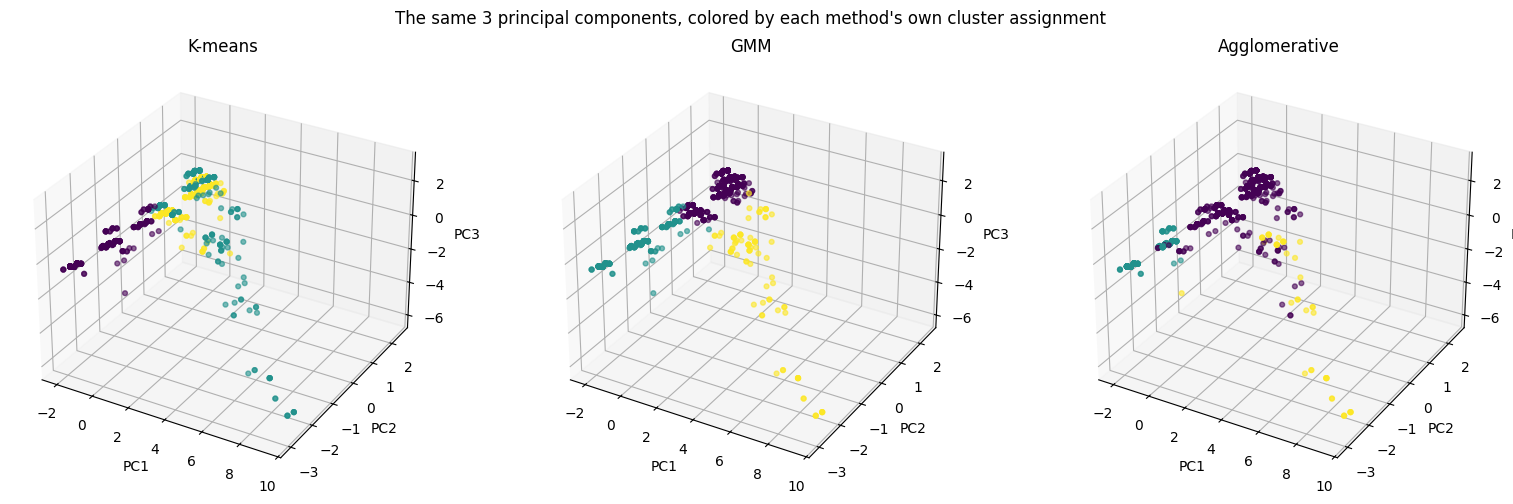

In [11]:

pca3 = PCA(n_components=3)
X_pca3 = pca3.fit_transform(X)

fig = plt.figure(figsize=(16, 5))
for i, (name, labels) in enumerate(results.items()):
    ax = fig.add_subplot(1, 3, i + 1, projection='3d')
    ax.scatter(X_pca3[:, 0], X_pca3[:, 1], X_pca3[:, 2], c=labels, cmap='viridis', s=12, alpha=0.6)
    ax.set_title(name)
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_zlabel('PC3')
plt.suptitle('The same 3 principal components, colored by each method\'s own cluster assignment')
plt.tight_layout()
plt.show()



**🔧 Try it yourself:** rotate all three and look for where they visibly disagree about a group of points near a boundary — those boundary regions are exactly where "which cluster does this belong to" is genuinely ambiguous, not a case of one method being simply wrong.



## Step 8: Everything side by side


In [12]:

summary_rows = []
for name, labels in results.items():
    summary_rows.append({
        'Method': name,
        'Silhouette': silhouette_score(X, labels),
        'Davies-Bouldin': davies_bouldin_score(X, labels),
        'ARI vs. Zurich class': adjusted_rand_score(zurich_codes, labels),
    })
summary_rows.append({'Method': 'Random baseline', 'Silhouette': baseline_silhouette,
                      'Davies-Bouldin': baseline_db, 'ARI vs. Zurich class': np.nan})
print(pd.DataFrame(summary_rows).round(3).to_string(index=False))

print(f"\nSemi-supervised (predicting will_flare, 5% labeled):")
print(f"  baseline={baseline_acc:.3f}  self-training={self_training_acc:.3f}  "
      f"label-propagation={label_prop_acc:.3f}  ceiling={ceiling_acc:.3f}")

print(f"\nAnomaly detection (severe-flare rate among flagged, overall rate={overall_severe_rate:.3f}):")
for name, flags in [('Isolation Forest', iso_flags), ('GMM likelihood', gmm_flags), ('LOF', lof_flags)]:
    print(f"  {name}: {flares.loc[flags, 'severe_flare'].mean():.3f}")


         Method  Silhouette  Davies-Bouldin  ARI vs. Zurich class
        K-means       0.225           1.847                 0.470
            GMM       0.202           1.805                 0.389
  Agglomerative       0.174           1.576                 0.160
Random baseline      -0.008          32.699                   NaN

Semi-supervised (predicting will_flare, 5% labeled):
  baseline=0.753  self-training=0.747  label-propagation=0.756  ceiling=0.775

Anomaly detection (severe-flare rate among flagged, overall rate=0.036):
  Isolation Forest: 0.103
  GMM likelihood: 0.131
  LOF: 0.000



## Closing discussion

Every comparison above used the identical real dataset and identical held-back ground truth, and asked three genuinely different algorithms to find the same kind of structure. Where they agreed, that's a stronger claim than any one of them succeeding alone. Where they disagreed — and check the numbers above honestly, because they may well have — that disagreement is itself the finding: it tells you the "right" way to group solar active regions depends on which mathematical notion of similarity or unusualness you commit to, not that one method is simply correct and the others are broken.

**Connect to your own work:** what's the equivalent "expensive label, cheap raw measurement" gap in your own subfield's solar or space-weather data — and which of today's three semi-supervised or three anomaly-detection methods would you reach for first, given what you now know about how they actually behave on real, messy observational data?
